# **Step2 -> "Entendimiento de los datos"**

##wd

In [1]:
### Mounting Google Drive :
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pwd

/content


In [2]:
working_dir = "/content/drive/MyDrive/1. 2026-2/Otros/1INF03 Analisis de Datos/Semana 2"
%cd $working_dir

/content/drive/MyDrive/1. 2026-2/Otros/1INF03 Analisis de Datos/Semana 2


In [3]:
!pwd

/content/drive/MyDrive/1. 2026-2/Otros/1INF03 Analisis de Datos/Semana 2


In [4]:
import pandas as pd

## **Archivo de datos: ECE_2S_2018_WEB_ad.sav**

Se cuenta con información de las siguientes variables:


In [5]:
!pip install pyreadstat
import pyreadstat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 28.8 MB/s eta 0:00:00


*   Hay 4 variables cualitativas
*   Hay 4 variables cuantitativas: 500_L, ...

In [6]:
datos = pd.read_spss("ECE_2S_2018_WEB_ad.sav")
print(datos.shape)
datos.head()

(535146, 19)


,ID_IE,ID_seccion,cor_est,nom_dre,nom_ugel,Departamento,Provincia,Distrito,Gestion2,Area,sexo,grupo_L,grupo_M,grupo_HGE,grupo_CT,M500_L,M500_M,M500_HGE,M500_CT
0,000001,01,01,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Mujer,En inicio,Previo al inicio,Previo al inicio,Previo al inicio,525.94,492.78,382.75,345.37
1,000001,01,02,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Hombre,En inicio,En inicio,En inicio,NaN,528.82,542.53,488.65,NaN
2,000001,01,03,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Mujer,En inicio,Previo al inicio,En inicio,En proceso,548.64,456.86,449.52,569.90
3,000001,01,04,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Hombre,En proceso,En inicio,En proceso,En proceso,589.68,550.23,521.37,549.93
4,000001,01,05,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Hombre,Previo al inicio,Previo al inicio,En proceso,Previo al inicio,492.67,508.46,517.61,295.11


**Tipos de variables**

In [7]:
datos.dtypes

,0
ID_IE,object
ID_seccion,object
cor_est,object
nom_dre,object
nom_ugel,object
Departamento,object
Provincia,object
Distrito,object
Gestion2,category
Area,category


In [ ]:
#datos.M500_CT = datos.M500_CT.astype('int64') # Esto da error porque tiene dentro los nan
#datos.dtypes

#datos['M500_CT'] = datos['M500_CT'].astype('Int64')
#datos.dtypes


## Omitimos duplicados

Se reporta y se guarda para que talvez las corrijan

In [8]:
print(datos.shape)
datos.drop_duplicates(inplace=True)
print(datos.shape)

(535146, 19)
(535146, 19)


## Verificamos valores positivos

Queremos solo valores positivos en las variables numéricas (aplica para este caso)   <-  Solo aplica para algunos casos !!


In [9]:
print(datos.shape)

columnas = ['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']
datos_con_negativos = datos[datos[columnas].lt(0).any(axis=1)]

datos_con_negativos.shape

(535146, 19)


(379, 19)

In [10]:
datos_con_negativos

,ID_IE,ID_seccion,cor_est,nom_dre,nom_ugel,Departamento,Provincia,Distrito,Gestion2,Area,sexo,grupo_L,grupo_M,grupo_HGE,grupo_CT,M500_L,M500_M,M500_HGE,M500_CT
1825,000020,04,10,Callao,(DRE) Callao,CALLAO,CALLAO,BELLAVISTA,Estatal,Urbana,Mujer,Previo al inicio,Previo al inicio,Previo al inicio,Previo al inicio,156.09,126.87,-11.16,-208.51
12343,000118,02,20,Ucayali,Coronel Portillo,UCAYALI,CORONEL PORTILLO,CALLERIA,Estatal,Urbana,Hombre,Previo al inicio,Previo al inicio,Previo al inicio,Previo al inicio,449.75,392.00,329.50,-39.07
12521,000119,02,15,Ucayali,Coronel Portillo,UCAYALI,CORONEL PORTILLO,YARINACOCHA,Estatal,Urbana,Mujer,En proceso,Previo al inicio,Previo al inicio,En proceso,631.19,512.74,-13.29,523.12
13136,000122,02,25,Ucayali,Atalaya,UCAYALI,ATALAYA,RAYMONDI,Estatal,Urbana,Hombre,Previo al inicio,Previo al inicio,Previo al inicio,Previo al inicio,504.65,457.07,-13.29,-184.25
17123,000159,06,25,Puno,Puno,PUNO,PUNO,PUNO,Estatal,Urbana,Mujer,En inicio,Previo al inicio,Previo al inicio,En inicio,508.27,464.49,-13.29,425.27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
532906,013229,01,25,Lima Metropolitana,07 San Borja,LIMA,LIMA,CHORRILLOS,No estatal,Urbana,Hombre,Previo al inicio,Previo al inicio,Previo al inicio,Previo al inicio,143.64,135.85,-14.72,-106.23
533527,013269,02,16,Ucayali,Coronel Portillo,UCAYALI,CORONEL PORTILLO,CALLERIA,Estatal,Urbana,Mujer,Previo al inicio,Previo al inicio,Previo al inicio,Previo al inicio,341.75,333.49,115.57,-38.00
533571,013274,01,03,Cusco,Anta,CUSCO,ANTA,ANTA,No estatal,Urbana,Mujer,NaN,NaN,Previo al inicio,Previo al inicio,NaN,NaN,-11.16,-38.00
533795,013286,01,09,Lima Metropolitana,01 San Juan de Miraflores,LIMA,LIMA,SAN JUAN DE MIRAFLORES,No estatal,Urbana,Hombre,Previo al inicio,Previo al inicio,Previo al inicio,Previo al inicio,201.96,203.13,-13.29,-184.25


Se reportan los datos que no tienen sentido como un negativo

In [11]:
columnas = ['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']
datos_sin_negativos = datos[~datos[columnas].lt(0).any(axis=1)]
print(datos_sin_negativos.shape)

(534767, 19)


In [12]:
datos_sin_negativos

,ID_IE,ID_seccion,cor_est,nom_dre,nom_ugel,Departamento,Provincia,Distrito,Gestion2,Area,sexo,grupo_L,grupo_M,grupo_HGE,grupo_CT,M500_L,M500_M,M500_HGE,M500_CT
0,000001,01,01,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Mujer,En inicio,Previo al inicio,Previo al inicio,Previo al inicio,525.94,492.78,382.75,345.37
1,000001,01,02,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Hombre,En inicio,En inicio,En inicio,NaN,528.82,542.53,488.65,NaN
2,000001,01,03,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Mujer,En inicio,Previo al inicio,En inicio,En proceso,548.64,456.86,449.52,569.90
3,000001,01,04,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Hombre,En proceso,En inicio,En proceso,En proceso,589.68,550.23,521.37,549.93
4,000001,01,05,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Hombre,Previo al inicio,Previo al inicio,En proceso,Previo al inicio,492.67,508.46,517.61,295.11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
535141,013366,01,11,Loreto,Ramón Castilla - Caballococha,LORETO,MARISCAL RAMÓN CASTILLA,PEBAS,Estatal,Rural,Mujer,Previo al inicio,Previo al inicio,En inicio,Previo al inicio,377.44,438.04,446.47,373.26
535142,013366,01,12,Loreto,Ramón Castilla - Caballococha,LORETO,MARISCAL RAMÓN CASTILLA,PEBAS,Estatal,Rural,Mujer,En inicio,Previo al inicio,En inicio,En inicio,507.80,446.67,446.47,392.96
535143,013366,01,13,Loreto,Ramón Castilla - Caballococha,LORETO,MARISCAL RAMÓN CASTILLA,PEBAS,Estatal,Rural,Hombre,Previo al inicio,Previo al inicio,En inicio,En inicio,465.48,396.49,431.74,416.02
535144,013366,01,14,Loreto,Ramón Castilla - Caballococha,LORETO,MARISCAL RAMÓN CASTILLA,PEBAS,Estatal,Rural,Hombre,En inicio,Previo al inicio,En inicio,En inicio,506.66,459.92,437.63,416.15


In [13]:
datosSN = datos_sin_negativos.copy()

## Contabilizamos vacíos

Se cuenta vacios antes de imputar datos

Para fines didácticos, contabilizamos y luego excluimos todas las filas que contengan celdas vacías. En Step3 veremos más opciones.

In [15]:
vacios = pd.DataFrame(datosSN.isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/datosSN.shape[0], 2)*100
vacios # Porcentaje!=proporcion

,vacios,vacios%
ID_IE,0,0.0
ID_seccion,0,0.0
cor_est,0,0.0
nom_dre,0,0.0
nom_ugel,0,0.0
Departamento,0,0.0
Provincia,0,0.0
Distrito,0,0.0
Gestion2,0,0.0
Area,0,0.0


Es importante mostrar al dueño de los datos cuanta informacion perdemos

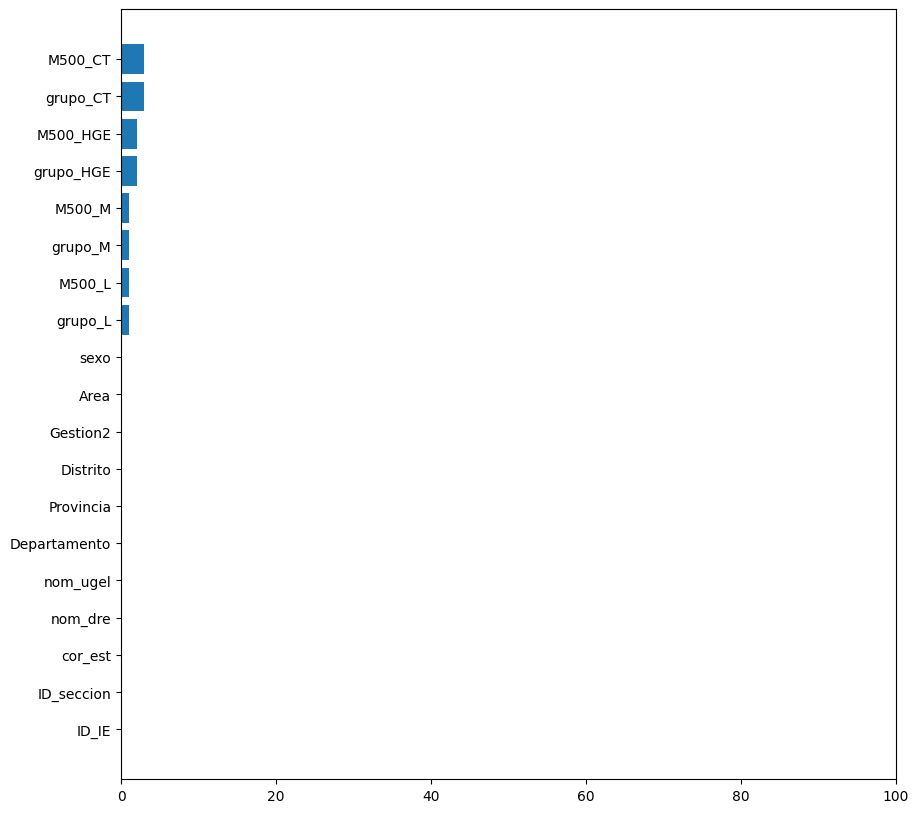

In [16]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10,10))
vac = np.arange(len(vacios['vacios%']))
plt.barh(vac, vacios['vacios%'])
plt.yticks(vac, vacios.index)
plt.xlim([0, 100])
plt.show()

In [17]:
#Excluimos vacíos
print(datosSN.shape)
datosSN.dropna(inplace=True)
print(datosSN.shape)

(534767, 19)
(516227, 19)


In [18]:
#Contabilizamos vacíos
vacios = pd.DataFrame(datosSN.isnull().sum()).sort_values(0,ascending=True)
vacios.columns = ['vacios']
vacios['vacios%'] = round(vacios['vacios']/datosSN.shape[0], 2)*100
vacios

,vacios,vacios%
ID_IE,0,0.0
ID_seccion,0,0.0
cor_est,0,0.0
nom_dre,0,0.0
nom_ugel,0,0.0
Departamento,0,0.0
Provincia,0,0.0
Distrito,0,0.0
Gestion2,0,0.0
Area,0,0.0


In [ ]:
#datos.M500_CT = datos.M500_CT.astype('int64')
#datos.dtypes

## Resumen para Variables Categóricas (cualitativas)

In [19]:
datosSN.head(3)

,ID_IE,ID_seccion,cor_est,nom_dre,nom_ugel,Departamento,Provincia,Distrito,Gestion2,Area,sexo,grupo_L,grupo_M,grupo_HGE,grupo_CT,M500_L,M500_M,M500_HGE,M500_CT
0,000001,01,01,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Mujer,En inicio,Previo al inicio,Previo al inicio,Previo al inicio,525.94,492.78,382.75,345.37
2,000001,01,03,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Mujer,En inicio,Previo al inicio,En inicio,En proceso,548.64,456.86,449.52,569.90
3,000001,01,04,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Hombre,En proceso,En inicio,En proceso,En proceso,589.68,550.23,521.37,549.93


In [20]:
datosSN.dtypes

,0
ID_IE,object
ID_seccion,object
cor_est,object
nom_dre,object
nom_ugel,object
Departamento,object
Provincia,object
Distrito,object
Gestion2,category
Area,category


In [21]:
datosSN_vCategoricas = datosSN.select_dtypes(include=['category']) # Las extraigo para no afectar a las que parecen categoricas, pero no lo son como los IDs o correlativos
datosSN_vCategoricas

,Gestion2,Area,sexo,grupo_L,grupo_M,grupo_HGE,grupo_CT
0,Estatal,Rural,Mujer,En inicio,Previo al inicio,Previo al inicio,Previo al inicio
2,Estatal,Rural,Mujer,En inicio,Previo al inicio,En inicio,En proceso
3,Estatal,Rural,Hombre,En proceso,En inicio,En proceso,En proceso
4,Estatal,Rural,Hombre,Previo al inicio,Previo al inicio,En proceso,Previo al inicio
5,Estatal,Rural,Hombre,En inicio,En inicio,En proceso,En inicio
...,...,...,...,...,...,...,...
535140,Estatal,Rural,Mujer,Previo al inicio,Previo al inicio,En inicio,En inicio
535141,Estatal,Rural,Mujer,Previo al inicio,Previo al inicio,En inicio,Previo al inicio
535142,Estatal,Rural,Mujer,En inicio,Previo al inicio,En inicio,En inicio
535143,Estatal,Rural,Hombre,Previo al inicio,Previo al inicio,En inicio,En inicio


### Categorías distintas

In [22]:
datosSN_vCategoricas['grupo_CT'].nunique()

4

In [23]:
datosSN_vCategoricas['grupo_CT'].unique()

['Previo al inicio', 'En proceso', 'En inicio', 'Satisfactorio']
Categories (4, object): ['En inicio', 'En proceso', 'Previo al inicio', 'Satisfactorio']

### Moda

La moda nos da ideas de la frecuencia mas alta

In [35]:
datosSN_vCategoricas['grupo_CT'].mode()[0]

'En inicio'

In [36]:
datosSN_vCategoricas['grupo_HGE'].mode()[0]

'En proceso'

In [37]:
datosSN_vCategoricas['Area'].mode()[0]

'Urbana'

### Frecuencia absoluta

In [38]:
datosSN_vCategoricas['Gestion2'].value_counts()

,count
Gestion2,
Estatal,392228
No estatal,123999


Tablas cruzadas cuando tengo mas de una variable

In [39]:
datosSN_vCategoricas[['Area', 'Gestion2']].value_counts()

Area    Gestion2  
Urbana  Estatal       338040
        No estatal    122650
Rural   Estatal        54188
        No estatal      1349
Name: count, dtype: int64

### Frecuencia relativa

In [40]:
datosSN_vCategoricas['Gestion2'].value_counts(normalize=True)

,proportion
Gestion2,
Estatal,0.759798
No estatal,0.240202


Se tiene que tener en cuenta si es proporciones del total de la tabla o columna

In [41]:
datosSN_vCategoricas[['Area', 'Gestion2']].value_counts(normalize=True)

Area    Gestion2  
Urbana  Estatal       0.654828
        No estatal    0.237589
Rural   Estatal       0.104969
        No estatal    0.002613
Name: proportion, dtype: float64

### Tablas cruzadas

Frecuencias absolutas

In [42]:
pd.crosstab(datosSN_vCategoricas['Area'], datosSN_vCategoricas['Gestion2'])

Gestion2,Estatal,No estatal
Area,,
Rural,54188,1349
Urbana,338040,122650


Frecuencias relaticas respecto solo al total de la tabla

In [43]:
pd.crosstab(datosSN_vCategoricas['Area'], datosSN_vCategoricas['Gestion2'], normalize=True) # Es para proporciones

Gestion2,Estatal,No estatal
Area,,
Rural,0.104969,0.002613
Urbana,0.654828,0.237589


Frecuencias relativas respecto al rotal de fila

In [44]:
pd.crosstab(datosSN_vCategoricas['Area'], datosSN_vCategoricas['Gestion2'], normalize='index')

Gestion2,Estatal,No estatal
Area,,
Rural,0.975710,0.024290
Urbana,0.733769,0.266231


Frecuencias relativas respecto al rotal de columna

In [45]:
pd.crosstab(datosSN_vCategoricas['Area'], datosSN_vCategoricas['Gestion2'], normalize='columns')

Gestion2,Estatal,No estatal
Area,,
Rural,0.138154,0.010879
Urbana,0.861846,0.989121


## Resumen para Variables Numéricas

In [46]:
datosSN.head(3)

,ID_IE,ID_seccion,cor_est,nom_dre,nom_ugel,Departamento,Provincia,Distrito,Gestion2,Area,sexo,grupo_L,grupo_M,grupo_HGE,grupo_CT,M500_L,M500_M,M500_HGE,M500_CT
0,000001,01,01,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Mujer,En inicio,Previo al inicio,Previo al inicio,Previo al inicio,525.94,492.78,382.75,345.37
2,000001,01,03,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Mujer,En inicio,Previo al inicio,En inicio,En proceso,548.64,456.86,449.52,569.90
3,000001,01,04,Piura,Huarmaca,PIURA,HUANCABAMBA,HUARMACA,Estatal,Rural,Hombre,En proceso,En inicio,En proceso,En proceso,589.68,550.23,521.37,549.93


In [47]:
datosSN.dtypes

,0
ID_IE,object
ID_seccion,object
cor_est,object
nom_dre,object
nom_ugel,object
Departamento,object
Provincia,object
Distrito,object
Gestion2,category
Area,category


In [48]:
datosSN_vNumericas = datosSN.select_dtypes(include=['float64']) # Solo incluyo a los que son numericas, pero tmb se debe tomar en cuenta al Integro
datosSN_vNumericas

,M500_L,M500_M,M500_HGE,M500_CT
0,525.94,492.78,382.75,345.37
2,548.64,456.86,449.52,569.90
3,589.68,550.23,521.37,549.93
4,492.67,508.46,517.61,295.11
5,569.40,565.98,546.88,470.44
...,...,...,...,...
535140,500.57,508.46,447.29,426.88
535141,377.44,438.04,446.47,373.26
535142,507.80,446.67,446.47,392.96
535143,465.48,396.49,431.74,416.02


### **Medidas de Tendencia Central**

In [49]:
#Media
#np.mean(datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']])
datosSN_vNumericas.mean()

,0
M500_L,572.044009
M500_M,561.599370
M500_HGE,497.130583
M500_CT,501.525030


In [50]:
#Mediana
datosSN_vNumericas.median()

,0
M500_L,569.53
M500_M,557.78
M500_HGE,492.31
M500_CT,498.73


Los alias de cuantiles es en percentiles
*   Q1: 0.25
*   Q2: 0.5: El valor central se encuentra como maximo en estos valores
*   Q3: 0.75:

In [51]:
#Cuantil
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].quantile([0.25, 0.50, 0.75])
datosSN_vNumericas.quantile([0.25, 0.50, 0.75])

,M500_L,M500_M,M500_HGE,M500_CT
0.25,521.73,501.40,431.74,441.89
0.50,569.53,557.78,492.31,498.73
0.75,619.28,610.67,558.67,569.90


*   Mejores calificaciones en L => Es la que tiende mas a la derecha (tiene sesgo)
*   Las que tiene peor nota es HGE

/tmp/ipykernel_3460/2804385979.py:13: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.bxp(stats, showfliers=False, patch_artist=True,


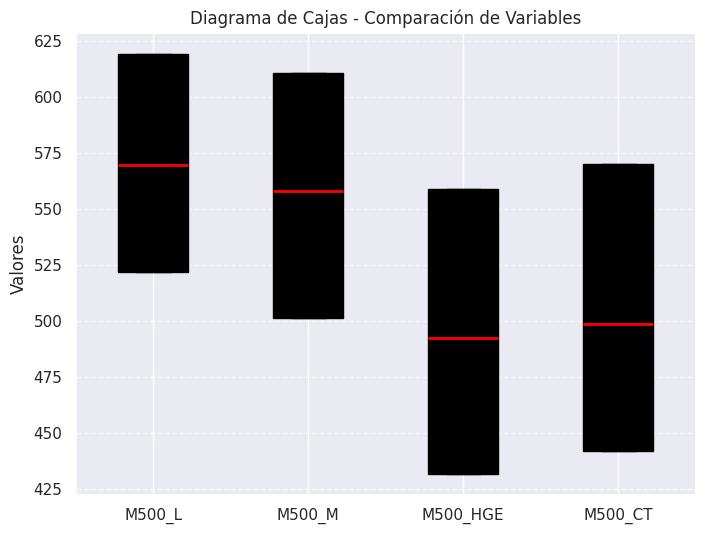

In [67]:
import matplotlib.pyplot as plt

# Diccionario con los estadísticos de la imagen
# Asumimos los bigotes (whislo, whishi) iguales a Q1 y Q3 al no tener el Min/Max de la muestra
stats = [
    {"label": "M500_L",   "q1": 521.73, "med": 569.53, "q3": 619.28, "whislo": 521.73, "whishi": 619.28},
    {"label": "M500_M",   "q1": 501.40, "med": 557.78, "q3": 610.67, "whislo": 501.40, "whishi": 610.67},
    {"label": "M500_HGE", "q1": 431.74, "med": 492.31, "q3": 558.67, "whislo": 431.74, "whishi": 558.67},
    {"label": "M500_CT",  "q1": 441.89, "med": 498.73, "q3": 569.90, "whislo": 441.89, "whishi": 569.90}
]

fig, ax = plt.subplots(figsize=(8, 6))
ax.bxp(stats, showfliers=False, patch_artist=True,
       boxprops=dict(facecolor="lightblue", color="black"),
       medianprops=dict(color="red", linewidth=2))

ax.set_title("Diagrama de Cajas - Comparación de Variables")
ax.set_ylabel("Valores")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### **Medidas de Variabilidad**

Todos son notas de cursos

In [52]:
#Min
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].min()
datosSN_vNumericas.min()

,0
M500_L,143.64
M500_M,126.87
M500_HGE,72.68
M500_CT,16.02


In [53]:
#Max
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].max()
datosSN_vNumericas.max()

,0
M500_L,919.76
M500_M,990.90
M500_HGE,1011.32
M500_CT,1171.11


In [54]:
#Rango: La dispersion de rango simple no es de confianza
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].max() - datos[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].min()
datosSN_vNumericas.max() - datosSN_vNumericas.min()

,0
M500_L,776.12
M500_M,864.03
M500_HGE,938.64
M500_CT,1155.09


In [55]:
#Rango Intercuartil: Este rango es mas util porque me dice que tanto se aleja el 50% de los datos centrales
#(datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].quantile([0.75])).values - (datos[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].quantile([0.25])).values
datosSN_vNumericas.quantile([0.75]).values - datosSN_vNumericas.quantile([0.25]).values # 128.01 dice que M500_CT es el mas disperso


array([[ 97.55, 109.27, 126.93, 128.01]])

In [56]:
#Varianza
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].var()
datosSN_vNumericas.var()

,0
M500_L,5211.187819
M500_M,7423.483460
M500_HGE,9090.066295
M500_CT,9736.923483


In [57]:
#Desviación Estandar: En promedio, los de M500_CT son los que se alejan mas => Dice la misma informacion que el RIC
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].std()
datosSN_vNumericas.std()

,0
M500_L,72.188557
M500_M,86.159639
M500_HGE,95.341839
M500_CT,98.675851


In [58]:
#Desviación Estandar
import math
print(math.sqrt(5272.595392))
print(math.sqrt(7477.205411))
print(math.sqrt(9244.621107))
print(math.sqrt(9930.958210))

72.61263934054456
86.47083560947009
96.1489527088049
99.65419313807122


In [59]:
#Coeficiente de variación
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].std() / datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].mean()
datosSN_vNumericas.std() / datosSN_vNumericas.mean()


,0
M500_L,0.126194
M500_M,0.153418
M500_HGE,0.191784
M500_CT,0.196752


### **Medidas de Deformación**

*   La mas asimetrica a la derecha es la del curso de Matematica
*   No hay asimetria negativa, por lo que la mayoria tiene notas altas

In [60]:
#Coeficiente de Asimetría
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].skew()
datosSN_vNumericas.skew()

,0
M500_L,0.140347
M500_M,0.488547
M500_HGE,0.224323
M500_CT,0.018836


No es muy comun reportar curtosis (asimetria horizontal)

In [61]:
#Coeficiente de Curtosis
#datosSN[['M500_L', 'M500_M', 'M500_HGE', 'M500_CT']].kurt()
datosSN_vNumericas.kurt()

,0
M500_L,0.488578
M500_M,1.112582
M500_HGE,0.533289
M500_CT,0.472035


## **Distribución marginal**

Hasta aqui hemos hecho analiis univariado. Analizaremos el Lenguaje y Matematica por separado

M500_L    572.044009
dtype: float64


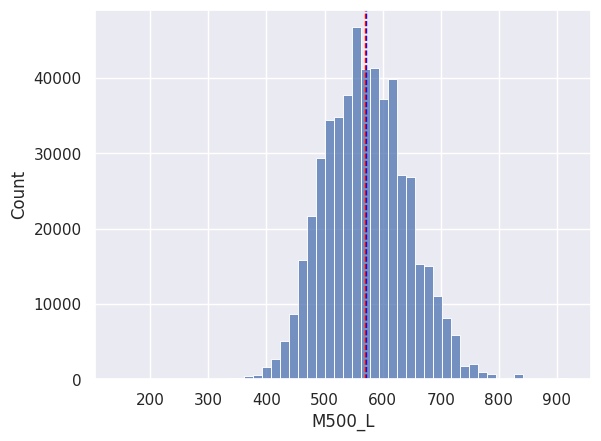

In [62]:
# libraries & dataset
import seaborn as sns
import matplotlib.pyplot as plt

print(datosSN[['M500_L']].mean())
sns.set(style="darkgrid")

plot = sns.histplot(datosSN["M500_L"], bins=50)

plt.axvline(datosSN["M500_L"].mean(), color='blue', linestyle='--', linewidth=1)
plt.axvline(datosSN["M500_L"].median(), color='red', linestyle='--', linewidth=1)

plt.show() # La media y mediana casi coincide asi que la distribucion puede ser casi normal

M500_M    561.59937
dtype: float64


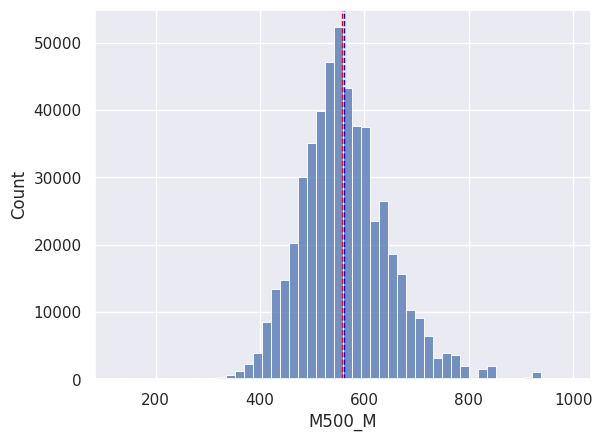

In [63]:
print(datosSN[['M500_M']].mean())
sns.set(style="darkgrid")

plot2 = sns.histplot(datosSN["M500_M"], bins=50)

plt.axvline(datosSN["M500_M"].mean(), color='blue', linestyle='--', linewidth=1)
plt.axvline(datosSN["M500_M"].median(), color='red', linestyle='--', linewidth=1)

plt.show() # La media y mediana casi coincide asi que la distribucion puede ser casi normal. La media esta ligeramente mas a la izquierda que la mediana

M500_HGE    497.130583
dtype: float64


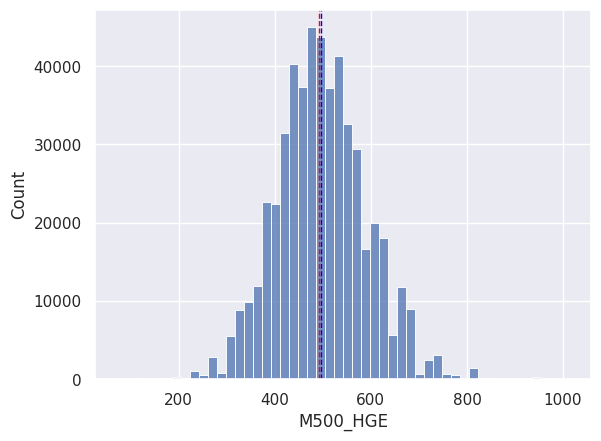

In [64]:
print(datosSN[['M500_HGE']].mean())
sns.set(style="darkgrid")

plot3 = sns.histplot(datosSN["M500_HGE"], bins=50)

plt.axvline(datosSN["M500_HGE"].mean(), color='blue', linestyle='--', linewidth=1)
plt.axvline(datosSN["M500_HGE"].median(), color='red', linestyle='--', linewidth=1)

plt.show()

M500_CT    501.52503
dtype: float64


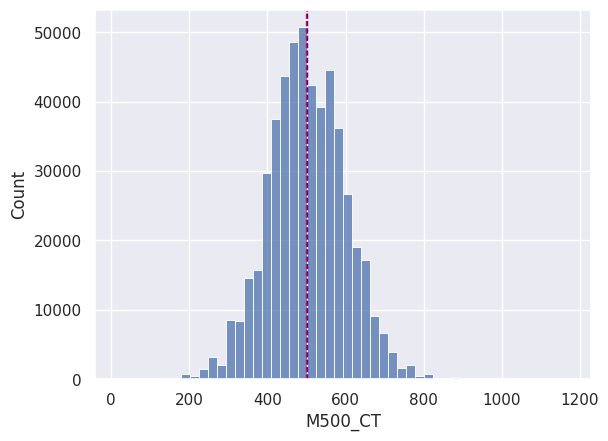

In [65]:
print(datosSN[['M500_CT']].mean())
sns.set(style="darkgrid")

plot3 = sns.histplot(datosSN["M500_CT"], bins=50)

plt.axvline(datosSN["M500_CT"].mean(), color='blue', linestyle='--', linewidth=1)
plt.axvline(datosSN["M500_CT"].median(), color='red', linestyle='--', linewidth=1)

plt.show()

## **Distribución Condicional**

567.5132891727723
559.21


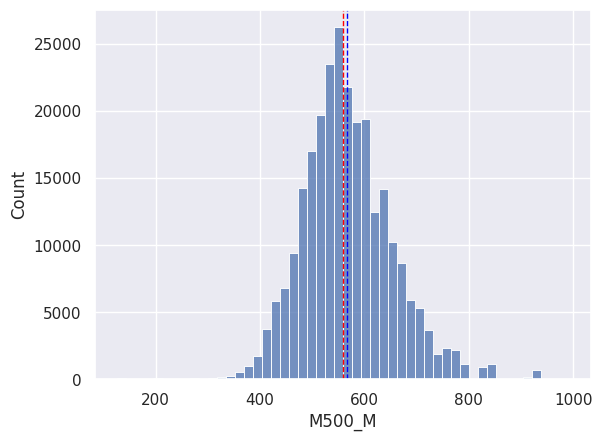

In [68]:
sns.set(style="darkgrid")

plot3 = sns.histplot(datosSN[datosSN['sexo']=='Hombre'].M500_M, bins=50)

print(datosSN[datosSN['sexo']=='Hombre'].M500_M.mean())
print(datosSN[datosSN['sexo']=='Hombre'].M500_M.median())
plot3.axvline(datosSN[datosSN['sexo']=='Hombre'].M500_M.mean(), color='blue', linestyle='--', linewidth=1)
plot3.axvline(datosSN[datosSN['sexo']=='Hombre'].M500_M.median(), color='red', linestyle='--', linewidth=1)

plt.show() # Analisis individual de hombres

555.5082684896815
550.23


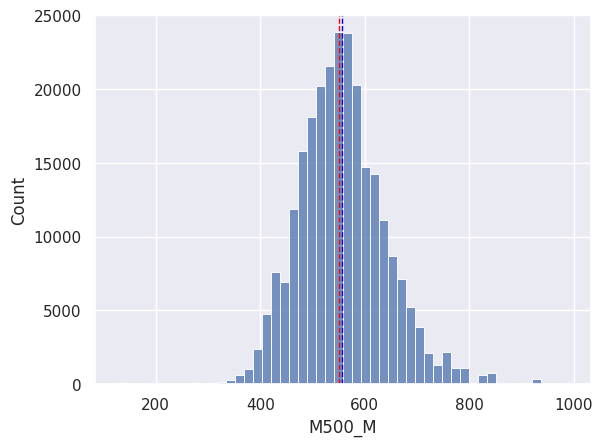

In [69]:
sns.set(style="darkgrid")

plot3 = sns.histplot(datosSN[datosSN['sexo']=='Mujer'].M500_M, bins=50)

print(datosSN[datosSN['sexo']=='Mujer'].M500_M.mean())
print(datosSN[datosSN['sexo']=='Mujer'].M500_M.median())
plot3.axvline(datosSN[datosSN['sexo']=='Mujer'].M500_M.mean(), color='blue', linestyle='--', linewidth=1)
plot3.axvline(datosSN[datosSN['sexo']=='Mujer'].M500_M.median(), color='red', linestyle='--', linewidth=1)

plt.show() # Analisis individual de mujeres

Antes teniamos analizado todo con la varaible sexo. Hemos analizado por separado, por lo que la presencia de x sí altera a y
*   La marginal es mi referencia
*   La condicional es cuando x=Hombre o x=Mujer

/tmp/ipykernel_3460/1927799310.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  sns.histplot(datosSN[datos['sexo']=='Hombre'].M500_M, bins=50, color="blue", label="Condicional H", kde=True)


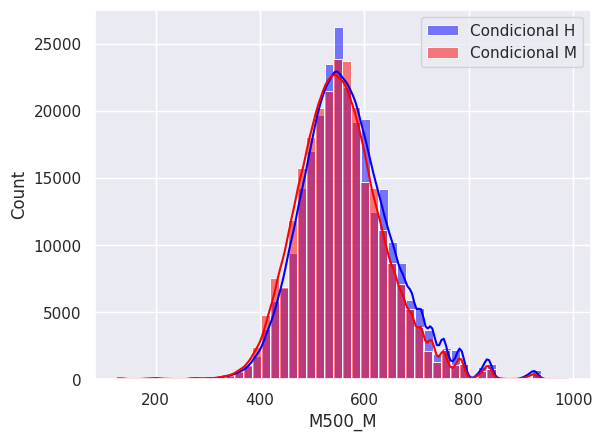

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="darkgrid")
sns.histplot(datosSN[datos['sexo']=='Hombre'].M500_M, bins=50, color="blue", label="Condicional H", kde=True)
sns.histplot(datosSN[datosSN['sexo']=='Mujer'].M500_M, bins=50, color="red", label="Condicional M", kde=True)
plt.legend()
plt.show() # No hay diferencia muy marcada

*   La altura de la verde no importa porque es conteo
*   La verde es la referencia

/tmp/ipykernel_3460/2195322813.py:6: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  sns.histplot(datosSN[datos['sexo']=='Hombre'].M500_M, bins=50, color="blue", label="Condicional H", kde=True)


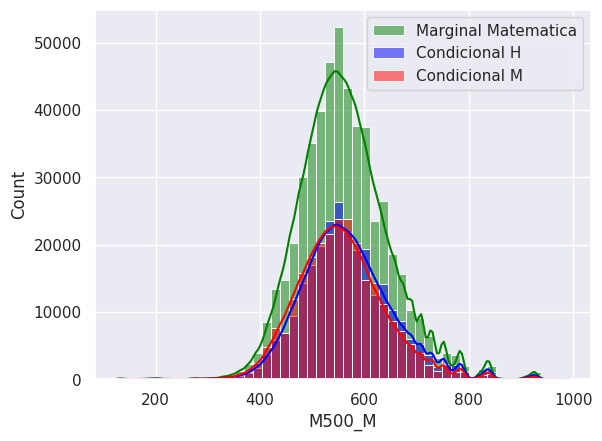

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="darkgrid")
sns.histplot(datosSN["M500_M"], bins=50, color="green", label="Marginal Matematica", kde=True)
sns.histplot(datosSN[datos['sexo']=='Hombre'].M500_M, bins=50, color="blue", label="Condicional H", kde=True)
sns.histplot(datosSN[datosSN['sexo']=='Mujer'].M500_M, bins=50, color="red", label="Condicional M", kde=True)
plt.legend()
plt.show()

Las notas de los estudiantes de colegios no totales suelen ser mayores que los de no estatales. En un grafico formal, no debe estar la referencia

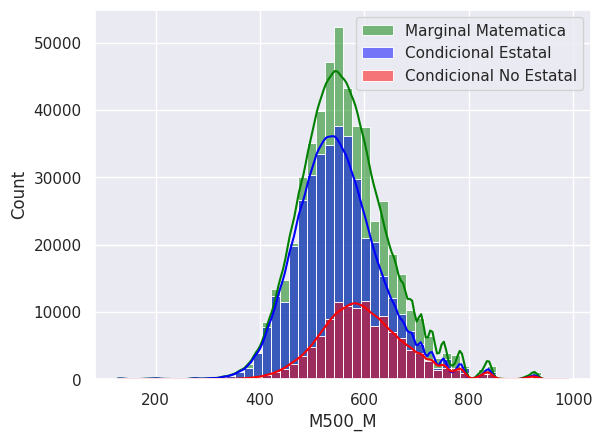

In [72]:
sns.set(style="darkgrid")
sns.histplot(datosSN["M500_M"], bins=50, color="green", label="Marginal Matematica", kde=True)
sns.histplot(datosSN[datosSN['Gestion2']=='Estatal'].M500_M, bins=50, color="blue", label="Condicional Estatal", kde=True)
sns.histplot(datosSN[datosSN['Gestion2']=='No estatal'].M500_M, bins=50, color="red", label="Condicional No Estatal", kde=True)
plt.legend()
plt.show()

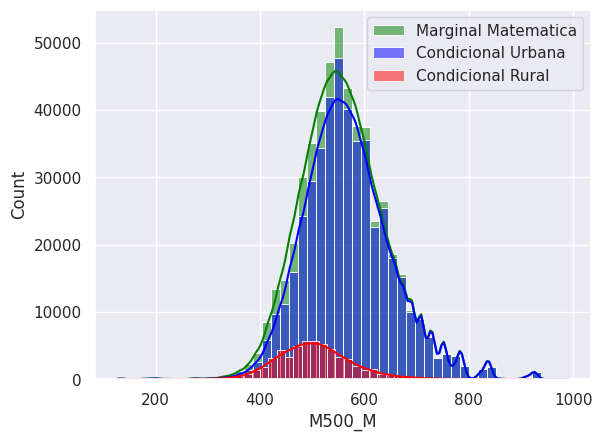

In [73]:
sns.set(style="darkgrid")
sns.histplot(datosSN["M500_M"], bins=50, color="green", label="Marginal Matematica", kde=True)
sns.histplot(datosSN[datosSN['Area']=='Urbana'].M500_M, bins=50, color="blue", label="Condicional Urbana", kde=True)
sns.histplot(datosSN[datosSN['Area']=='Rural'].M500_M, bins=50, color="red", label="Condicional Rural", kde=True)
plt.legend()
plt.show()

/tmp/ipykernel_3460/1077906822.py:6: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  sns.histplot(datosSN[datos['sexo']=='Hombre'].M500_L, bins=50, color="blue", label="Condicional H", kde=True)


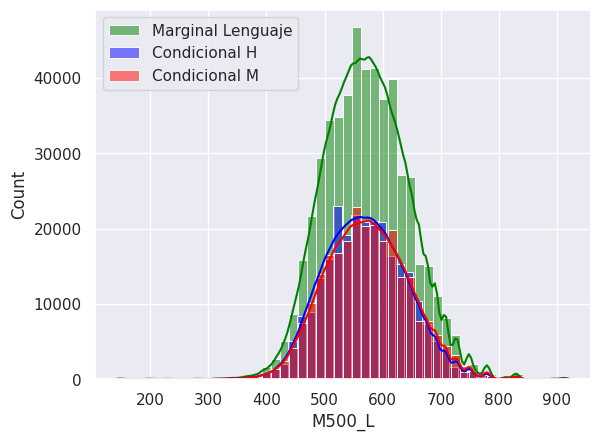

In [74]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="darkgrid")
sns.histplot(datosSN["M500_L"], bins=50, color="green", label="Marginal Lenguaje", kde=True)
sns.histplot(datosSN[datos['sexo']=='Hombre'].M500_L, bins=50, color="blue", label="Condicional H", kde=True)
sns.histplot(datosSN[datosSN['sexo']=='Mujer'].M500_L, bins=50, color="red", label="Condicional M", kde=True)
plt.legend()
plt.show()

Asi vemos la asociacion entre 2 variables

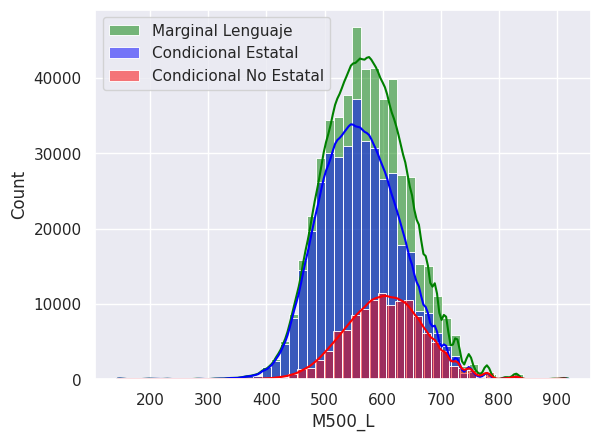

In [75]:
sns.set(style="darkgrid")
sns.histplot(datosSN["M500_L"], bins=50, color="green", label="Marginal Lenguaje", kde=True)
sns.histplot(datosSN[datosSN['Gestion2']=='Estatal'].M500_L, bins=50, color="blue", label="Condicional Estatal", kde=True)
sns.histplot(datosSN[datosSN['Gestion2']=='No estatal'].M500_L, bins=50, color="red", label="Condicional No Estatal", kde=True)
plt.legend()
plt.show()

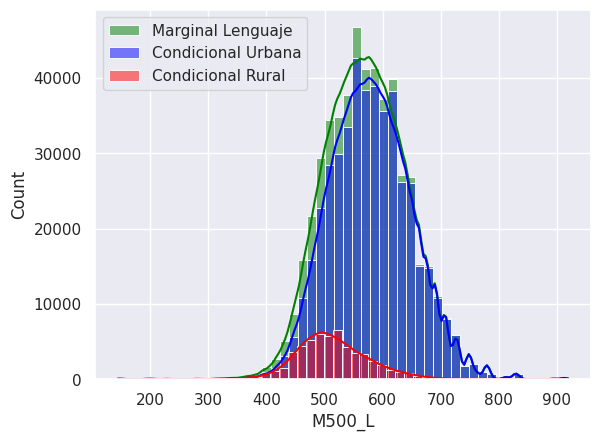

In [76]:
sns.set(style="darkgrid")
sns.histplot(datosSN["M500_L"], bins=50, color="green", label="Marginal Lenguaje", kde=True)
sns.histplot(datosSN[datosSN['Area']=='Urbana'].M500_L, bins=50, color="blue", label="Condicional Urbana", kde=True)
sns.histplot(datosSN[datosSN['Area']=='Rural'].M500_L, bins=50, color="red", label="Condicional Rural", kde=True)
plt.legend()
plt.show()